# Climate dataflow: spec section 7 at small scale

This notebook follows the data flow in `spec.txt` section 7 on a synthetic
dataset that is small enough to run anywhere:

1. **Ingestion**: a monthly sea-surface-temperature field
   `(time, lat, lon)` is written to a Zarr v2 directory. The Python bindings
   cannot write Zarr, so the notebook writes `.zgroup`, `.zarray`, `.zattrs`
   and chunk files directly, following the Zarr v2 specification.
2. **Lazy query**: `tpt_planetary.open_zarr` opens the array without reading
   chunk data. The whole-array mean is computed lazily and streamed chunk by
   chunk. The Pacific box is read as a sub-selection.
3. **Compute**: the Pacific box mean time series is plotted with matplotlib.
4. **Coordinate transformation**: time stamps are converted from UTC to TT
   with `tpt_planetary.utc_to_tt`.

The full spec example is a 600 x 720 x 1440 x 50 dataset read from S3. This
notebook uses 600 x 36 x 72 (5-degree grid), with NaN over a fixed land mask.
Coordinates are not CF-decoded; time is stored as days since 1975-01-01.

In [1]:
import json
import shutil
import tempfile
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tpt_planetary as tp

print("numpy", np.__version__, "| tpt_planetary", tp.__version__)

numpy 2.5.4 | tpt_planetary 0.1.0


## 1. Synthetic dataset

The field has a latitude-dependent climatology, a seasonal cycle, a slow
warming trend, an ENSO-like Pacific anomaly and noise. A fixed land mask is
set to NaN, so the NaN-aware reductions are exercised.

In [2]:
rng = np.random.default_rng(20240601)
n_time, n_lat, n_lon = 600, 36, 72
lat = np.arange(-87.5, 90.0, 5.0)           # 36 cell centres
lon = np.arange(2.5, 360.0, 5.0)            # 72 cell centres
t = np.arange(n_time, dtype=np.float64)     # months since 1975-01

LAT, LON = np.meshgrid(lat, lon, indexing="ij")
climatology = 26.0 + 4.0 * np.cos(np.deg2rad(LAT))
seasonal = 1.5 * np.sin(2 * np.pi * t / 12.0)[:, None, None] * np.sin(np.deg2rad(LAT))[None]
trend = 0.01 * t[:, None, None] / 12.0
enso = (0.8 * np.sin(2 * np.pi * t / 48.0)[:, None, None]
        * np.exp(-((LON - 200.0) / 60.0) ** 2)[None] * np.cos(np.deg2rad(LAT))[None])
noise = rng.normal(0.0, 0.2, size=(n_time, n_lat, n_lon))
sst = climatology[None] + seasonal + trend + enso + noise

land = (LON > 0.0) & (LON < 40.0) & (np.abs(LAT) < 35.0)
sst[:, land] = np.nan

time_days = t * 30.4375 + 15.0              # mid-month, days since 1975-01-01
print("field shape", sst.shape, "| bytes", sst.nbytes, "| NaN fraction", round(float(np.isnan(sst).mean()), 3))

field shape (600, 36, 72) | bytes 12441600 | NaN fraction 0.043


## 2. Write a Zarr v2 directory by hand

Zarr v2 layout: `root/.zgroup`, then one directory per array holding
`.zarray` (shape, chunks, dtype, fill value, compressor, order), `.zattrs`
(user attributes, here `_ARRAY_DIMENSIONS`) and chunk files named
`i.j.k` (the `.` chunk key separator). Chunks are little-endian `<f8`, C order,
and uncompressed (`"compressor": null`).

In [3]:
def write_zarr_v2(root, name, data, chunks, dims, attrs=None):
    """Write a float64 array as a Zarr v2 array directory under `root`."""
    arr_dir = root / name
    arr_dir.mkdir(parents=True, exist_ok=True)
    data = np.ascontiguousarray(data, dtype="<f8")
    zarray = {
        "zarr_format": 2,
        "shape": list(data.shape),
        "chunks": list(chunks),
        "dtype": "<f8",
        "compressor": None,
        "fill_value": "NaN",
        "order": "C",
        "filters": None,
    }
    (arr_dir / ".zarray").write_text(json.dumps(zarray, indent=2))
    zattrs = {"_ARRAY_DIMENSIONS": list(dims), **(attrs or {})}
    (arr_dir / ".zattrs").write_text(json.dumps(zattrs, indent=2))
    grid = [-(-s // c) for s, c in zip(data.shape, chunks)]   # ceil division
    for idx in np.ndindex(*grid):
        sl = tuple(slice(i * c, min((i + 1) * c, s)) for i, c, s in zip(idx, chunks, data.shape))
        block = data[sl]
        if block.shape != tuple(chunks):                    # pad edge chunks to full size
            padded = np.full(chunks, np.nan, dtype="<f8")
            padded[tuple(slice(0, n) for n in block.shape)] = block
            block = padded
        (arr_dir / ".".join(map(str, idx))).write_bytes(block.tobytes(order="C"))
    return arr_dir

workdir = Path(tempfile.mkdtemp(prefix="tpt-climate-"))
store = workdir / "climate.zarr"
store.mkdir()
(store / ".zgroup").write_text(json.dumps({"zarr_format": 2}))

write_zarr_v2(store, "sst", sst, chunks=(12, 18, 36), dims=("time", "lat", "lon"),
              attrs={"units": "degC", "long_name": "synthetic sea surface temperature"})
write_zarr_v2(store, "time", time_days, chunks=(600,), dims=("time",),
              attrs={"units": "days since 1975-01-01 00:00:00 UTC"})
write_zarr_v2(store, "lat", lat, chunks=(36,), dims=("lat",), attrs={"units": "degrees_north"})
write_zarr_v2(store, "lon", lon, chunks=(72,), dims=("lon",), attrs={"units": "degrees_east"})

n_chunks = len([p for p in (store / "sst").iterdir() if p.name[0].isdigit()])
print("chunk files written for sst:", n_chunks)
print(sorted(p.name for p in (store / "sst").iterdir() if not p.name[0].isdigit()))

chunk files written for sst:

 200
['.zarray', '.zattrs']


## 3. Lazy open and whole-array mean

`open_zarr` reads only the metadata. `ZarrArray.mean()` streams the chunks
through the lazy expression graph and skips NaN values, so the result should
match the in-memory NumPy mean.

In [4]:
zarr_sst = tp.open_zarr(store / "sst")
print(zarr_sst)
print("chunks:", zarr_sst.chunks, "| dtype:", zarr_sst.dtype)

lazy_mean = zarr_sst.mean()
numpy_mean = float(np.nanmean(sst))
print(f"lazy mean  = {lazy_mean:.6f}")
print(f"numpy mean = {numpy_mean:.6f}")
assert abs(lazy_mean - numpy_mean) < 1e-9, "lazy mean disagrees with NumPy"
print("agreement: OK")

ZarrArray(path="", shape=[600, 36, 72], chunks=[12, 18, 36], dtype="<f8")
chunks: (12, 18, 36) | dtype: <f8


lazy mean  = 28.746025
numpy mean = 28.746025
agreement: OK


## 4. Pacific box: last ten years

Spec section 7 asks for the mean over the Pacific for the last 10 years.
`ZarrArray.read` takes a selection and returns NumPy data, and only the chunks
that intersect the selection are decoded. The Python binding has no
slice-then-reduce call, so the reduction over the box is done with NumPy on
the selected block.

In [5]:
def box_indices(lat_range, lon_range):
    la = np.where((lat >= lat_range[0]) & (lat <= lat_range[1]))[0]
    lo = np.where((lon >= lon_range[0]) & (lon <= lon_range[1]))[0]
    return slice(int(la[0]), int(la[-1]) + 1), slice(int(lo[0]), int(lo[-1]) + 1)

lat_sl, lon_sl = box_indices((-30.0, 30.0), (140.0, 260.0))
last_120 = slice(n_time - 120, n_time)

box_last10 = zarr_sst.read((last_120, lat_sl, lon_sl))
print("selected block shape:", box_last10.shape)
pacific_last10 = float(np.nanmean(box_last10))
reference = float(np.nanmean(sst[last_120, lat_sl, lon_sl]))
print(f"Pacific mean, last 120 months: {pacific_last10:.4f} (in-memory reference {reference:.4f})")
assert abs(pacific_last10 - reference) < 1e-9

selected block shape: (120, 12, 24)
Pacific mean, last 120 months: 30.3427 (in-memory reference 30.3427)


## 5. Plot the Pacific box time series

The monthly Pacific box mean covers the full 50 years, so the ENSO-like
anomaly and the trend are both visible.

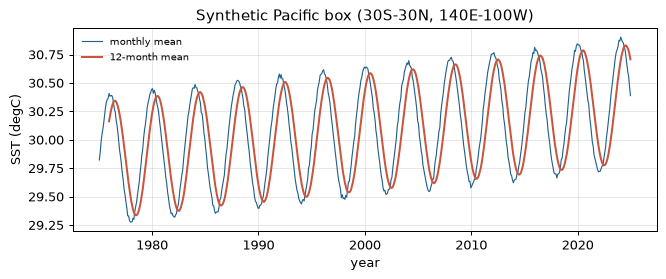

In [6]:
pacific_all = zarr_sst.read((slice(None), lat_sl, lon_sl))
series = np.nanmean(pacific_all, axis=(1, 2))

years = 1975 + time_days / 365.25
fig, ax = plt.subplots(figsize=(7.5, 3.2), dpi=90)
ax.plot(years, series, lw=0.9, color="#1f5f8b", label="monthly mean")
smooth = np.convolve(series, np.ones(12) / 12, mode="valid")
ax.plot(years[11:], smooth, lw=1.6, color="#c8553d", label="12-month mean")
ax.set_xlabel("year")
ax.set_ylabel("SST (degC)")
ax.set_title("Synthetic Pacific box (30S-30N, 140E-100W)")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 6. UTC to TT

`tpt_planetary.utc_to_tt` converts a two-part `JulianDate` from UTC to TT.
Three mid-month time stamps are converted. The difference is TT - UTC in
seconds: 32.184 s (TT - TAI) plus the accumulated leap seconds.

In [7]:
def days_to_date(days_since_1975):
    return date(1975, 1, 1) + timedelta(days=float(days_since_1975))

rows = []
for idx in (0, 299, 599):
    d = days_to_date(time_days[idx])
    utc = tp.JulianDate.from_calendar(d.year, d.month, d.day, 12 * 3600.0)
    tt = tp.utc_to_tt(utc)
    rows.append((d.isoformat(), utc.to_float(), tt.to_float(), tt.seconds_since(utc)))

print(f"{'UTC date':<12} {'JD (UTC)':>16} {'JD (TT)':>16} {'TT - UTC [s]':>14}")
for iso, jd_utc, jd_tt, dt in rows:
    print(f"{iso:<12} {jd_utc:>16.6f} {jd_tt:>16.6f} {dt:>14.3f}")

UTC date             JD (UTC)          JD (TT)   TT - UTC [s]
1975-01-16     2442429.000000   2442429.000535         46.184
1999-12-16     2451529.000000   2451529.000743         64.184
2024-12-16     2460661.000000   2460661.000801         69.184


The Zarr directory lives in a temporary folder, which is removed here.

In [8]:
shutil.rmtree(workdir)
print("temporary Zarr store removed")

temporary Zarr store removed
